# Selección sencilla de variables para modelar el Índice de Aridez (IA) de Sinaloa

**Objetivo:** comparar grupos pequeños de variables TerraClimate y obtener una recomendación inicial de cuáles conservar, cuáles probar por separado y cuáles no incluir de inicio.

Este cuadernillo utiliza los archivos que ya existen; **no descarga datos ni modifica los GeoTIFF originales**. Usa `rasterio` para leer los GeoTIFF y `scikit-learn` para comparar modelos.

> **Importante:** el IA anual se calcula a partir de PPT anual / ETP anual. Por eso, PPT y ETP del mismo año no se incluyen como predictores en esta comparación: darían al modelo acceso directo a los componentes del objetivo. Los predictores TerraClimate se agregan a año calendario: `aet`, `def` y `ro` se suman; las otras variables se promedian.

## 1. Qué variables vamos a comparar

- **Candidatas iniciales:** `tmmn`, `tmmx`, `soil`, `srad`, `vs`.
- **Humedad atmosférica:** comparar `vap` o `vpd`.
- **Agua superficial y evapotranspiración:** probar `ro` y `aet` como aportes adicionales.
- **Sensibilidad:** `def` y `pdsi`, porque están vinculadas al balance hídrico/sequía.
- **Índices climáticos de gran escala:** `PDO_jun_oct` y `RONI_temporada_lluvias`, cargados desde el CSV que genera el cuadernillo de descarga de índices NOAA. También se probarán sus valores del año anterior (`*_rezago1`).

**Importante:** PDO y RONI son series temporales globales/regionales, no capas espaciales. Su valor se repite en los píxeles de un mismo año. Por eso la evaluación separa años completos entre entrenamiento y prueba, para evitar que píxeles del mismo año queden en ambos conjuntos.

El IA anual se calcula a partir de PPT anual / ETP anual. Por eso, PPT y ETP del mismo año no se incluyen como predictores en esta comparación: darían al modelo acceso directo a los componentes del objetivo. Los índices NOAA se usan aquí como predictores explicativos contemporáneos; para un pronóstico real hecho antes de terminar el año, se deben preferir sus valores rezagados y variables disponibles en la fecha de predicción.

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)

# Ejecuta el notebook desde la carpeta raíz del proyecto de tesis.
DIR_IA = Path("indice_aridez_anual") / "malla_4km"
DIR_EXTRA = Path("variables_adicionales_terraclimate")
DIR_SALIDA = Path("indice_aridez_anual") / "seleccion_variables_modelos"
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

BANDAS = ["aet", "def", "pdsi", "soil", "srad", "tmmn", "tmmx", "vap", "vpd", "vs", "ro"]
TOTALES = {"aet", "def", "ro"}  # suma anual; las demás variables se promedian
NODATA_FALLBACK = -9999.0
MAX_PIXELES_POR_ANIO = 2500
SEMILLA = 42

print("IA anual:", DIR_IA.resolve())
print("Variables TerraClimate:", DIR_EXTRA.resolve())
print("Resultados:", DIR_SALIDA.resolve())

IA anual: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis\indice_aridez_anual\malla_4km
Variables TerraClimate: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis\variables_adicionales_terraclimate
Resultados: C:\Users\Leon1\Documents\Maestria\Semestre III\Movilidad\Tesis\indice_aridez_anual\seleccion_variables_modelos


## 2. Encontrar años disponibles y comprobar archivos

La celda busca años con el mapa anual de IA y los 12 GeoTIFF mensuales de variables adicionales. Si no encuentra archivos, revisa que el notebook se ejecute desde la carpeta raíz del proyecto.

In [2]:
pat_extra = re.compile(r"^tc_extra_(\d{4})_(0[1-9]|1[0-2])\.tif$", re.I)
pat_ia = re.compile(r"^IA_anual_(\d{4})\.tif$", re.I)
extra = {}
for p in DIR_EXTRA.glob("tc_extra_*.tif"):
    m = pat_extra.match(p.name)
    if m:
        extra[(int(m.group(1)), int(m.group(2)))] = p
ia_paths = {}
for p in DIR_IA.glob("IA_anual_*.tif"):
    m = pat_ia.match(p.name)
    if m:
        ia_paths[int(m.group(1))] = p

years = sorted(y for y in ia_paths if all((y, m) in extra for m in range(1, 13)))
if not years:
    raise FileNotFoundError("No hay años con IA anual y los 12 archivos tc_extra_YYYY_MM.tif. Comprueba las carpetas y nombres.")

inventario = pd.DataFrame({
    "anio": sorted(set([y for y, m in extra])),
})
inventario["12_meses_extra"] = inventario["anio"].apply(lambda y: all((int(y), m) in extra for m in range(1, 13)))
inventario["IA_anual"] = inventario["anio"].apply(lambda y: int(y) in ia_paths)
display(inventario.tail(15))
print(f"Años utilizables: {years[0]}–{years[-1]} ({len(years)} años)")
print(f"Total de GeoTIFF mensuales detectados: {len(extra)}")
if len(years) < 5:
    raise ValueError("Hay menos de 5 años utilizables. Para comparar modelos temporalmente se necesitan más años.")

,anio,12_meses_extra,IA_anual
52,2010,True,True
53,2011,True,True
54,2012,True,True
55,2013,True,True
56,2014,True,True
57,2015,True,True
58,2016,True,True
59,2017,True,True
60,2018,True,True
61,2019,True,True


Años utilizables: 1958–2024 (67 años)
Total de GeoTIFF mensuales detectados: 804


## 3. Leer IA y agregar las 11 variables a escala anual

Se exige que las capas tengan exactamente la misma malla que el IA. Si no coinciden, el cuadernillo se detiene en lugar de emparejar píxeles incorrectamente. Para no sesgar el resultado, cada píxel debe tener los 12 meses válidos de cada variable.

In [3]:
def clean(a, nodata):
    a = np.asarray(a, dtype="float32")
    bad = ~np.isfinite(a)
    if nodata is not None:
        bad |= (a == nodata)
    bad |= (a == NODATA_FALLBACK)
    a = a.copy()
    a[bad] = np.nan
    return a

def meta_of(src):
    return (src.width, src.height, src.crs, src.transform)

def read_ia(path, reference_meta=None):
    with rasterio.open(path) as src:
        meta = meta_of(src)
        arr = clean(src.read(1), src.nodata)
    if reference_meta is not None and meta != reference_meta:
        raise ValueError(f"La malla de {path.name} no coincide con la malla de referencia.")
    return arr, meta

# La primera capa IA define la malla de referencia.
first_ia, META_REF = read_ia(ia_paths[years[0]])

def read_month_var(path, var):
    with rasterio.open(path) as src:
        if meta_of(src) != META_REF:
            raise ValueError(f"La malla de {path.name} no coincide con IA.")
        if src.count != len(BANDAS):
            raise ValueError(f"{path.name}: se esperaban 11 bandas y hay {src.count}.")
        desc = [(d or "").strip().lower() for d in src.descriptions]
        band = desc.index(var) + 1 if var in desc else BANDAS.index(var) + 1
        arr = clean(src.read(band), src.nodata)
    return arr

rng = np.random.default_rng(SEMILLA)
blocks = []
resumen_anual = []

for year in years:
    ia, _ = read_ia(ia_paths[year], META_REF)
    monthly = {v: [] for v in BANDAS}
    for month in range(1, 13):
        path = extra[(year, month)]
        for var in BANDAS:
            monthly[var].append(read_month_var(path, var))

    annual = {}
    for var in BANDAS:
        stack = np.stack(monthly[var], axis=0)
        valid = np.isfinite(stack).all(axis=0)
        if var in TOTALES:
            a = np.sum(np.where(np.isfinite(stack), stack, 0), axis=0)
        else:
            a = np.nanmean(stack, axis=0)
        a[~valid] = np.nan
        annual[var] = a

    mask = np.isfinite(ia)
    for var in BANDAS:
        mask &= np.isfinite(annual[var])
    idx = np.flatnonzero(mask)
    if idx.size == 0:
        print(f"Aviso: {year} no tiene píxeles completos y se omite.")
        continue
    n = min(MAX_PIXELES_POR_ANIO, idx.size)
    idx = rng.choice(idx, size=n, replace=False)
    row = pd.DataFrame({"anio": year, "IA": ia.ravel()[idx]})
    for var in BANDAS:
        row[var] = annual[var].ravel()[idx]
    blocks.append(row)
    resumen_anual.append({"anio": year, "pixeles_validos": int(mask.sum()), "pixeles_muestreados": n})

data = pd.concat(blocks, ignore_index=True)
resumen_muestreo = pd.DataFrame(resumen_anual)
resumen_muestreo.to_csv(DIR_SALIDA / "01_resumen_muestreo.csv", index=False)
print("Filas de píxel-año:", len(data))
print("Años incluidos:", sorted(data.anio.unique()))
display(resumen_muestreo)
display(data.head())

# Cargar PDO y RONI preparados por Cuadernillo_variables_extra_aridez_Sinaloa.ipynb.
# No se descargan datos aquí: el CSV debe existir localmente.
RUTA_INDICES_ANUALES = Path("indices_climaticos_noaa") / "indices_anuales_y_temporadas.csv"
if not RUTA_INDICES_ANUALES.exists():
    raise FileNotFoundError(
        f"No existe {RUTA_INDICES_ANUALES}. Ejecuta primero la sección de índices NOAA/RONI "
        "del cuadernillo Cuadernillo_variables_extra_aridez_Sinaloa.ipynb, cuando tengas los CSV disponibles."
    )

indices = pd.read_csv(RUTA_INDICES_ANUALES)
if "anio" not in indices.columns:
    raise ValueError(f"El archivo {RUTA_INDICES_ANUALES} debe contener una columna 'anio'.")

# Variables principales (temporada de lluvias) y sus rezagos de un año.
INDICES_MODELO = [
    "PDO_jun_oct",
    "RONI_temporada_lluvias",
    "PDO_jun_oct_rezago1",
    "RONI_temporada_lluvias_rezago1",
]
faltan = [c for c in INDICES_MODELO if c not in indices.columns]
if faltan:
    raise ValueError(
        "Faltan columnas de PDO/RONI en indices_anuales_y_temporadas.csv: " + ", ".join(faltan) +
        ". Revisa que la sección de descarga y construcción de índices haya terminado correctamente."
    )

indices = indices[["anio"] + INDICES_MODELO].copy()
indices["anio"] = pd.to_numeric(indices["anio"], errors="coerce")
indices = indices.dropna(subset=["anio"]).drop_duplicates("anio", keep="last")
indices["anio"] = indices["anio"].astype(int)
data["anio"] = data["anio"].astype(int)
data = data.merge(indices, on="anio", how="left", validate="many_to_one")

# Para comparar todos los modelos con exactamente los mismos años/píxeles, exigir
# que PDO, RONI y sus rezagos estén disponibles. Se informa qué años se excluyen.
anios_antes_indices = sorted(data["anio"].unique())
validos_indices = data.groupby("anio")[INDICES_MODELO].apply(lambda x: x.notna().all().all())
anios_validos_indices = sorted(validos_indices[validos_indices].index.astype(int).tolist())
anios_excluidos_indices = sorted(set(anios_antes_indices) - set(anios_validos_indices))
if len(anios_validos_indices) < 5:
    raise ValueError(
        "Hay menos de 5 años con PDO, RONI y sus rezagos completos. Comprueba el CSV de índices NOAA; "
        "no se imputarán índices ausentes automáticamente."
    )
data = data[data["anio"].isin(anios_validos_indices)].copy()
print("Años válidos con PDO/RONI y rezagos:", f"{min(anios_validos_indices)}–{max(anios_validos_indices)}", f"({len(anios_validos_indices)} años)")
if anios_excluidos_indices:
    print("Años excluidos por falta de índices:", anios_excluidos_indices)
print("Columnas NOAA añadidas:", INDICES_MODELO)
display(data[["anio", "IA"] + INDICES_MODELO].drop_duplicates("anio").sort_values("anio").tail(10))


Filas de píxel-año: 167500
Años incluidos: [np.int64(1958), np.int64(1959), np.int64(1960), np.int64(1961), np.int64(1962), np.int64(1963), np.int64(1964), np.int64(1965), np.int64(1966), np.int64(1967), np.int64(1968), np.int64(1969), np.int64(1970), np.int64(1971), np.int64(1972), np.int64(1973), np.int64(1974), np.int64(1975), np.int64(1976), np.int64(1977), np.int64(1978), np.int64(1979), np.int64(1980), np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(201

,anio,pixeles_validos,pixeles_muestreados
0,1958,4206,2500
1,1959,4206,2500
2,1960,4206,2500
3,1961,4206,2500
4,1962,4206,2500
...,...,...,...
62,2020,4206,2500
63,2021,4206,2500
64,2022,4206,2500
65,2023,4206,2500


,anio,IA,aet,def,pdsi,soil,srad,tmmn,tmmx,vap,vpd,vs,ro
0,1958,1.003375,1199.000000,341.800018,3.472500,256.008331,202.783325,17.591667,29.516665,1.752917,1.366667,2.253333,346.0
1,1958,0.711442,1022.100037,685.699951,2.175000,38.441669,205.350037,15.374999,32.000000,1.428333,1.928333,2.225833,190.0
2,1958,0.667530,936.099976,762.700012,3.120000,38.883331,200.100021,17.225000,33.583332,1.795583,1.904167,2.206667,200.0
3,1958,0.699675,1000.099915,661.899902,2.600000,75.033340,203.000000,16.941668,32.483330,1.730417,1.780000,2.168333,161.0
4,1958,0.413604,664.800049,1049.400024,3.131667,26.441666,202.708313,17.025000,31.491667,1.980083,1.415833,3.181667,43.0


Años válidos con PDO/RONI y rezagos: 1958–2024 (67 años)
Columnas NOAA añadidas: ['PDO_jun_oct', 'RONI_temporada_lluvias', 'PDO_jun_oct_rezago1', 'RONI_temporada_lluvias_rezago1']


,anio,IA,PDO_jun_oct,RONI_temporada_lluvias,PDO_jun_oct_rezago1,RONI_temporada_lluvias_rezago1
142500,2015,0.745972,0.9366,1.650,0.2384,0.075
145000,2016,0.574394,0.0808,-0.850,0.9366,1.650
147500,2017,0.259416,-0.2940,-0.525,0.0808,-0.850
150000,2018,0.325286,-0.4772,0.325,-0.2940,-0.525
152500,2019,0.518075,-0.3076,0.025,-0.4772,0.325
155000,2020,0.210489,-1.1920,-1.050,-0.3076,0.025
157500,2021,0.263611,-1.9974,-0.850,-1.1920,-1.050
160000,2022,0.425532,-1.9238,-1.000,-1.9974,-0.850
162500,2023,0.294974,-2.3564,0.900,-1.9238,-1.000
165000,2024,0.231042,-2.6916,-0.650,-2.3564,0.900


## 4. Identificar variables redundantes

La matriz principal usa correlación de Spearman entre las 11 variables TerraClimate. Un valor absoluto cercano a 1 indica que dos variables se mueven de forma parecida; **no implica automáticamente que una deba eliminarse**. Se listan los pares con |rho| ≥ 0.85.

Además, se calcula una correlación exploratoria entre PDO/RONI y el IA medio por año. Como PDO y RONI tienen un único valor por año para toda la región, esta segunda tabla se calcula a escala anual y no tratando cada píxel como una observación independiente.

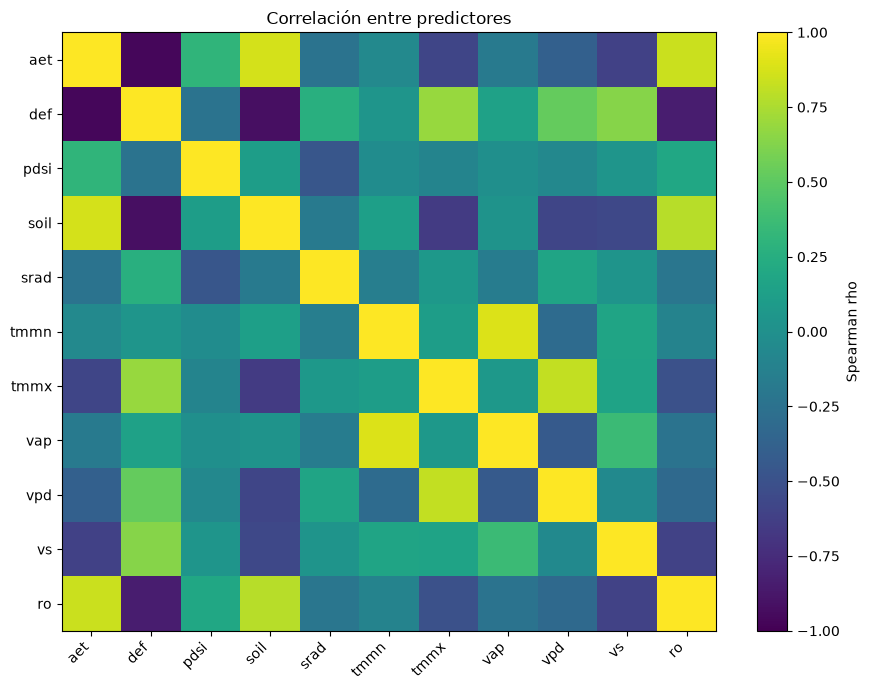

,aet,def,pdsi,soil,srad,tmmn,tmmx,vap,vpd,vs,ro
aet,1.00,-0.97,0.31,0.87,-0.24,-0.06,-0.58,-0.19,-0.38,-0.61,0.84
def,-0.97,1.00,-0.24,-0.92,0.26,0.04,0.69,0.15,0.53,0.64,-0.84
pdsi,0.31,-0.24,1.00,0.12,-0.46,-0.02,-0.10,-0.00,-0.07,0.04,0.19
soil,0.87,-0.92,0.12,1.00,-0.18,0.13,-0.65,0.02,-0.58,-0.57,0.79
srad,-0.24,0.26,-0.46,-0.18,1.00,-0.14,0.07,-0.16,0.17,0.04,-0.21
tmmn,-0.06,0.04,-0.02,0.13,-0.14,1.00,0.12,0.89,-0.30,0.17,-0.11
tmmx,-0.58,0.69,-0.10,-0.65,0.07,0.12,1.00,0.06,0.82,0.16,-0.50
vap,-0.19,0.15,-0.00,0.02,-0.16,0.89,0.06,1.00,-0.43,0.36,-0.24
vpd,-0.38,0.53,-0.07,-0.58,0.17,-0.30,0.82,-0.43,1.00,-0.05,-0.32
vs,-0.61,0.64,0.04,-0.57,0.04,0.17,0.16,0.36,-0.05,1.00,-0.60


Pares con |rho| >= 0.85:


,variable_1,variable_2,spearman_rho
0,aet,def,-0.967263
2,def,soil,-0.918281
3,tmmn,vap,0.891571
1,aet,soil,0.874905


Correlación temporal anual de PDO/RONI con el IA medio (exploratoria):


,spearman_rho_con_IA_medio_anual
PDO_jun_oct,0.418
RONI_temporada_lluvias,0.257
PDO_jun_oct_rezago1,0.189
RONI_temporada_lluvias_rezago1,-0.113


In [4]:
corr = data[BANDAS].corr(method="spearman")
corr.to_csv(DIR_SALIDA / "02_correlacion_variables_spearman.csv")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1, aspect="auto")
fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_xticks(range(len(BANDAS),), BANDAS, rotation=45, ha="right")
ax.set_yticks(range(len(BANDAS)), BANDAS)
ax.set_title("Correlación entre predictores")
fig.tight_layout()
plt.show()
display(corr.round(2))

pairs = []
for i, a in enumerate(BANDAS):
    for b in BANDAS[i+1:]:
        r = corr.loc[a, b]
        if np.isfinite(r) and abs(r) >= 0.85:
            pairs.append({"variable_1": a, "variable_2": b, "spearman_rho": r})
pairs_df = pd.DataFrame(pairs, columns=["variable_1", "variable_2", "spearman_rho"])
if not pairs_df.empty:
    pairs_df = pairs_df.sort_values("spearman_rho", key=lambda s: s.abs(), ascending=False)
pairs_df.to_csv(DIR_SALIDA / "03_pares_redundantes_rho085.csv", index=False)
print("Pares con |rho| >= 0.85:")
display(pairs_df)

# Correlación temporal anual: primero resumir espacialmente IA y predictores, después
# correlacionar años (no píxeles), para no inflar artificialmente el tamaño muestral.
resumen_temporal = data.groupby("anio")[ ["IA"] + BANDAS + INDICES_MODELO ].mean(numeric_only=True)
corr_temporal = resumen_temporal.corr(method="spearman").loc[["IA"], INDICES_MODELO].T
corr_temporal = corr_temporal.rename(columns={"IA": "spearman_rho_con_IA_medio_anual"})
corr_temporal.to_csv(DIR_SALIDA / "03b_correlacion_anual_PDO_RONI_IA.csv")
print("Correlación temporal anual de PDO/RONI con el IA medio (exploratoria):")
display(corr_temporal.sort_values("spearman_rho_con_IA_medio_anual", key=lambda s: s.abs(), ascending=False).round(3))


## 5. Comparar grupos de variables con los mismos años de prueba

Los últimos ~20 % de años se reservan para prueba; el modelo no ve esos años durante el entrenamiento. Se comparan grupos de variables TerraClimate y combinaciones con PDO/RONI. Los índices se agregan a todos los píxeles del mismo año, pero el corte se hace por años completos para evitar fuga temporal.

Los grupos con índices permiten responder si PDO, RONI o sus valores rezagados mejoran la predicción frente a las variables locales. Como la disponibilidad de índices puede reducir el periodo, todos los grupos se comparan sobre el mismo conjunto de años y píxeles completos.

Años de entrenamiento: 1958–2010
Años de prueba: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


C:\Users\Leon1\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Leon1\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Leon1\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Leon1\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.util

,modelo,n_variables,variables,RMSE,MAE,R2
6,M7_sensibilidad_def_pdsi,10,"tmmn, tmmx, soil, srad, vs, vap, ro, aet, def,...",0.020959,0.013019,0.988903
7,M8_todas_11,11,"aet, def, pdsi, soil, srad, tmmn, tmmx, vap, v...",0.021118,0.013059,0.988733
12,M13_todas_11_PDO_RONI,13,"aet, def, pdsi, soil, srad, tmmn, tmmx, vap, v...",0.022111,0.013477,0.987649
5,M6_vap_ro_aet,8,"tmmn, tmmx, soil, srad, vs, vap, ro, aet",0.028191,0.017681,0.979922
3,M4_vap_ro,7,"tmmn, tmmx, soil, srad, vs, vap, ro",0.039577,0.025170,0.960429
4,M5_vpd_ro,7,"tmmn, tmmx, soil, srad, vs, vpd, ro",0.041769,0.025783,0.955925
2,M3_base_vpd,6,"tmmn, tmmx, soil, srad, vs, vpd",0.094304,0.070149,0.775330
0,M1_base,5,"tmmn, tmmx, soil, srad, vs",0.094474,0.069983,0.774520
1,M2_base_vap,6,"tmmn, tmmx, soil, srad, vs, vap",0.096676,0.071854,0.763885
9,M10_base_RONI,6,"tmmn, tmmx, soil, srad, vs, RONI_temporada_llu...",0.099536,0.073147,0.749706


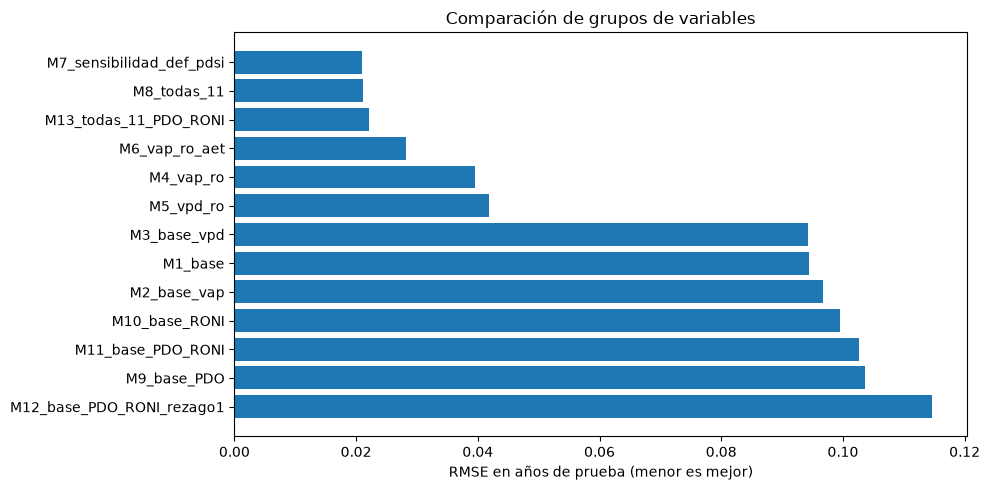

In [5]:
grupos = {
    "M1_base": ["tmmn", "tmmx", "soil", "srad", "vs"],
    "M2_base_vap": ["tmmn", "tmmx", "soil", "srad", "vs", "vap"],
    "M3_base_vpd": ["tmmn", "tmmx", "soil", "srad", "vs", "vpd"],
    "M4_vap_ro": ["tmmn", "tmmx", "soil", "srad", "vs", "vap", "ro"],
    "M5_vpd_ro": ["tmmn", "tmmx", "soil", "srad", "vs", "vpd", "ro"],
    "M6_vap_ro_aet": ["tmmn", "tmmx", "soil", "srad", "vs", "vap", "ro", "aet"],
    "M7_sensibilidad_def_pdsi": ["tmmn", "tmmx", "soil", "srad", "vs", "vap", "ro", "aet", "def", "pdsi"],
    "M8_todas_11": BANDAS.copy(),
    "M9_base_PDO": ["tmmn", "tmmx", "soil", "srad", "vs", "PDO_jun_oct"],
    "M10_base_RONI": ["tmmn", "tmmx", "soil", "srad", "vs", "RONI_temporada_lluvias"],
    "M11_base_PDO_RONI": ["tmmn", "tmmx", "soil", "srad", "vs", "PDO_jun_oct", "RONI_temporada_lluvias"],
    "M12_base_PDO_RONI_rezago1": ["tmmn", "tmmx", "soil", "srad", "vs", "PDO_jun_oct_rezago1", "RONI_temporada_lluvias_rezago1"],
    "M13_todas_11_PDO_RONI": BANDAS.copy() + ["PDO_jun_oct", "RONI_temporada_lluvias"],
}

years_ok = sorted(data.anio.unique())
n_test = max(1, int(np.ceil(0.20 * len(years_ok))))
if len(years_ok) - n_test < 3:
    raise ValueError("Muy pocos años para separar entrenamiento y prueba temporalmente.")
years_test = years_ok[-n_test:]
train = data[~data.anio.isin(years_test)].copy()
test = data[data.anio.isin(years_test)].copy()
print("Años de entrenamiento:", f"{train.anio.min()}–{train.anio.max()}")
print("Años de prueba:", years_test)

metrics = []
models = {}
for name, features in grupos.items():
    model = RandomForestRegressor(
        n_estimators=250, min_samples_leaf=3, max_features=0.8,
        random_state=SEMILLA, n_jobs=-1
    )
    model.fit(train[features], train["IA"])
    pred = model.predict(test[features])
    rmse = float(np.sqrt(mean_squared_error(test["IA"], pred)))
    mae = float(mean_absolute_error(test["IA"], pred))
    r2 = float(r2_score(test["IA"], pred)) if test["IA"].nunique() > 1 else np.nan
    metrics.append({"modelo": name, "n_variables": len(features), "variables": ", ".join(features),
                    "RMSE": rmse, "MAE": mae, "R2": r2})
    models[name] = model

metricas = pd.DataFrame(metrics).sort_values("RMSE")
metricas.to_csv(DIR_SALIDA / "04_comparacion_modelos.csv", index=False)
display(metricas)
fig, ax = plt.subplots(figsize=(10, 5))
plot = metricas.sort_values("RMSE", ascending=True)
ax.barh(plot["modelo"], plot["RMSE"])
ax.set_xlabel("RMSE en años de prueba (menor es mejor)")
ax.set_title("Comparación de grupos de variables")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## 6. Importancia de variables en el mejor grupo

Se calcula importancia por permutación en el conjunto de prueba. Es una señal de utilidad predictiva, no una explicación causal. Si dos variables están muy correlacionadas, la importancia puede repartirse entre ambas; por eso debe leerse junto con la matriz de correlación.

Mejor grupo por RMSE: M7_sensibilidad_def_pdsi


,variable,importancia_media,desviacion
6,ro,0.146294,0.000454
8,def,0.066751,0.000333
7,aet,0.049854,0.000297
2,soil,0.005209,0.000070
9,pdsi,0.002384,0.000049
3,srad,0.000297,0.000024
1,tmmx,0.000250,0.000023
0,tmmn,-0.000185,0.000019
4,vs,-0.000200,0.000015
5,vap,-0.000516,0.000024


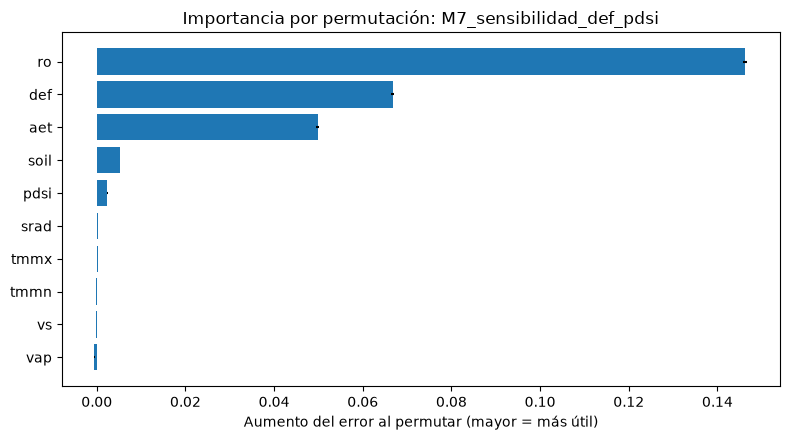

In [6]:
mejor_nombre = metricas.iloc[0]["modelo"]
mejor_features = grupos[mejor_nombre]
mejor_modelo = models[mejor_nombre]
perm = permutation_importance(
    mejor_modelo, test[mejor_features], test["IA"],
    n_repeats=5, random_state=SEMILLA,
    scoring="neg_root_mean_squared_error", n_jobs=-1
)
importancia = pd.DataFrame({
    "variable": mejor_features,
    "importancia_media": perm.importances_mean,
    "desviacion": perm.importances_std,
}).sort_values("importancia_media", ascending=False)
importancia.to_csv(DIR_SALIDA / "05_importancia_permutacion_mejor_modelo.csv", index=False)
print("Mejor grupo por RMSE:", mejor_nombre)
display(importancia)
fig, ax = plt.subplots(figsize=(8, 4.5))
p = importancia.sort_values("importancia_media")
ax.barh(p["variable"], p["importancia_media"], xerr=p["desviacion"])
ax.set_xlabel("Aumento del error al permutar (mayor = más útil)")
ax.set_title(f"Importancia por permutación: {mejor_nombre}")
fig.tight_layout()
plt.show()

## 7. Cómo tomar la decisión

- **Conservar provisionalmente** el grupo con menor RMSE si también tiene MAE competitivo y su resultado no depende de una sola variable redundante.
- **Elegir `vap` o `vpd`** según el desempeño en prueba y la matriz de correlación.
- **Añadir `ro` o `aet`** solo si mejora el error de prueba de forma apreciable.
- **Evaluar PDO y RONI por separado y juntos:** compara `M9`, `M10` y `M11` con el modelo base. Si bajan RMSE/MAE en años no vistos, podrían aportar información climática de gran escala. `M12` evalúa sus valores rezagados.
- **No incluir `def` y `pdsi` automáticamente**: compara los modelos de sensibilidad y documenta que son indicadores relacionados con el balance hídrico/sequía.
- No uses PPT/ETP contemporáneas para demostrar que las variables adicionales estiman el IA: el IA ya se deriva de PPT/ETP.
- Los índices PDO/RONI son valores temporales compartidos por toda la región; no son predictores espaciales independientes. La prueba se separa por años completos. La correlación anual con IA es exploratoria y no demuestra causalidad.
- Si el objetivo es pronosticar IA antes de que termine el año, prioriza las variables rezagadas y asegúrate de que todos los predictores estuvieran disponibles en la fecha real del pronóstico. Los modelos con valores del mismo año evalúan estimación retrospectiva, no un pronóstico anticipado.

**Limitación metodológica:** los píxeles dentro de un año están espacialmente relacionados. Para la evaluación final de tesis conviene añadir validación espacial por bloques o regiones.

Los archivos de salida quedan en `indice_aridez_anual/seleccion_variables_modelos/`:

- `01_resumen_muestreo.csv`
- `02_correlacion_variables_spearman.csv`
- `03_pares_redundantes_rho085.csv`
- `03b_correlacion_anual_PDO_RONI_IA.csv`
- `04_comparacion_modelos.csv`
- `05_importancia_permutacion_mejor_modelo.csv`